# Mood classification of spotify songs using Natural Language Processing and Text Analysis of Song Titles

**Final Year Project-2025/26**

### Project Goals 
| # | Goal |
|---|------|
| 1 | Data Curation & Text Preprocessing|
| 2 | Explonatory Text Analysis |
| 3 | Mood Classification |
| 4 | Popularity Prediction |
| 5 | System Evaluation |

**This project aims to develop a mood based music recommendation system using Natural Language Processing(NLP) techniques. 
The system analyzes song titles and emotional labels to identify textul patterns and generate relevant music recommendations based on emotional similarity**

## Section 1: Data Curation &  Text Preprocessing

### Required libraries

In [1]:
#Run only if libraries are missing 
#!pip install pandas numpy scikit-learn matplotlib seaborn nltk textblob 
#!pip uninstall wordcloud Pillow -y && pip install Pillow==9.5.0 && pip install wordcloud
#!pip install upsetplot -q


In [2]:
#Basic libraries
import re, warnings
import time
from collections import Counter
from itertools import chain

#Data Manupilation
import pandas as pd
import numpy as np

#Visualization
import matplotlib.pyplot as plt 
import seaborn as sns 
from wordcloud import WordCloud
from upsetplot import UpSet, from_memberships

#NLP
import nltk 
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer 
from textblob import TextBlob 

#Machine Learning
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

#Classification and Evaluation
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    classification_report, 
    confusion_matrix, 
    accuracy_score, 
    f1_score
)

warnings.filterwarnings("ignore")

In [3]:
sns.set_theme(style="whitegrid",palette="muted")
plt.rcParams["figure.dpi"]=110

nltk.download("stopwords",quiet=True)
nltk.download("punkt",quiet=True)

print("Libraries loaded")


Libraries loaded


In [4]:
df_songs=pd.read_csv("spotify_songs_eda.csv")
df_songs=df_songs.drop(columns=["track_id","keywords"],errors="ignore")
df_songs["emotion"]=df_songs["emotion"].str.lower().str.strip()

print(f"Shape: {df_songs.shape}")
print(f"Columns:{df_songs.columns.tolist()}")
print(f"Emotion counts:\n{df_songs['emotion'].value_counts().to_string()}")
print(f"Missing values:{df_songs.isnull().sum().sum()}")
print(f"Popularity: min= {df_songs['popularity'].min()} max={df_songs['popularity'].max()}")
df_songs.head(10)

Shape: (8029, 6)
Columns:['keyword', 'emotion', 'track_name', 'artist', 'popularity', 'release_date']
Emotion counts:
happy    2056
love     2006
sad      2001
party    1966
Missing values:0
Popularity: min= 0 max=97


,keyword,emotion,track_name,artist,popularity,release_date
0,happy,happy,The Happy Song,Imogen Heap,79,2016-10-17
1,happy,happy,Happy Birthday to You,Happy Birthday TA,51,2018-05-17
2,happy,happy,Happy Nation,Ace of Base,77,1992-11-16
3,happy,happy,Happy Birthday - Arabic,Mehmet Ellik,33,2013-01-01
4,happy,happy,"Happy - From ""Despicable Me 2""",Pharrell Williams,81,2014-03-03
5,happy,happy,Happy Birthday To You - Classic Version,Happy Birthday Songs,54,2021-02-12
6,happy,happy,Happy Birthday,Tempo,69,2021-12-09
7,happy,happy,Happy Birthday,Stevie Wonder,53,2002-10-29
8,happy,happy,Happy Birthday - original,Torsten Abrolat,33,2012-10-15
9,happy,happy,Happy Together,The Turtles,76,1967


#### Tokenization:

In [5]:
df_songs["tokens"]=df_songs["track_name"].apply(
    lambda x:re.sub(r"[^a-z\s]","",str(x).lower()).split())

print("Tokenization examples:")

for _,row in df_songs.sample(10).iterrows():
    print(f"'{row['track_name']}'=> {row['tokens']} ")

Tokenization examples:
'Scars Don't Speak'=> ['scars', 'dont', 'speak'] 
'Club'=> ['club'] 
'Miss You'=> ['miss', 'you'] 
'Mine'=> ['mine'] 
'Good bye (Acapella)'=> ['good', 'bye', 'acapella'] 
'FORGOTTEN'=> ['forgotten'] 
'Affection'=> ['affection'] 
'Golden Brown x Love Story'=> ['golden', 'brown', 'x', 'love', 'story'] 
'Hurts So Good'=> ['hurts', 'so', 'good'] 
'Good Vibes Only'=> ['good', 'vibes', 'only'] 


#### Removing stopwords

In [6]:
base_sw=set(stopwords.words("english"))
base_sw.update(["oh","yeah","ooh","ah","la","na","hey","got","get","let",
    "know","like","want","need","go","come","say","see","one",
    "make","take","give","put","way","day","time","back","still",
    "even","ever","never","always","feat","ft","remix","version",
    "remaster","remastered","edit","radio","original","mix","bonus","track",
    "your","mine","our","their","its","my","his","her",
    "we","you","they","them","are","was","were","been","the",
    "more","some","when","what","who","how","all","just","slowed", "reverb", "sped", "extended", "instrumental",
    "acoustic", "single", "live","song", "music", "dont", "inc", "non", "stop", "thing",
    "passo", "bem", "solto", "hronia", "polla", "mou",
    "better", "closer", "free", "dark", "funny"])

#each mood removes their own stopwords

emotion_keywords={
    "happy":{"happy","joy","smile","sunshine","good","vibes","feel","fun","bright",
        "dancing","alive","summer","glow","laughing","carefree","uplift","bliss",
        "shining","golden","joyride","high","spirits","mood","positivity"},
    
    "love" :{"love","heart","kiss","forever","baby","romance","soulmate","darling",
        "touch","desire","falling","mine","hold","passion","affection",
        "chemistry","devotion","endless","heartbeat","together","miss"},
    
    "sad"  :{"sad","lonely","broken","cry","tears","pain","hurt","goodbye",
        "heartbreak","fading","lost","alone","empty","numb","regrets",
        "scars","aching","shattered","blue","letting","distance","forgotten","silence"},
    
    "party":{"party","dance","club","beat","drop","bass","tonight","lights",
        "wild","crazy","banger","hype","turn","vibing","groove","rave",
        "festival","electric","nonstop","floor","filler","hands"}
}

def remove_sw(tokens,emotion):
    sw=base_sw | emotion_keywords.get(emotion,set())
    return [w for w in tokens if w not in sw and len(w)>2]

df_songs["clean_tokens"]=df_songs.apply(
    lambda r: remove_sw(r["tokens"],r["emotion"]),axis=1)
 
print("Stopwords removal examples for first 40 songs:")

print(df_songs["clean_tokens"].head(40))

Stopwords removal examples for first 40 songs:
0                              []
1                      [birthday]
2                        [nation]
3              [birthday, arabic]
4                    [despicable]
5             [birthday, classic]
6                      [birthday]
7                      [birthday]
8                      [birthday]
9                      [together]
10                     [birthday]
11             [birthday, habibi]
12                             []
13            [birthday, arabesk]
14                             []
15                    [new, year]
16              [birthday, dance]
17          [gia, genethlia, sou]
18                     [birthday]
19                    [xmas, war]
20                             []
21      [birthday, indian, style]
22                       [xronia]
23                  [harpy, hare]
24                          [end]
25                     [birthday]
26                     [birthday]
27             [birthday, indian]
2

#### Reducing words to root form

In [7]:
stemmer=PorterStemmer()

df_songs["stemmed_tokens"]=df_songs["clean_tokens"].apply(
    lambda tokens:[stemmer.stem(w) for w in tokens])

df_songs["clean_title"]  = df_songs["stemmed_tokens"].apply(lambda t: " ".join(t))
df_songs["title_length"] = df_songs["tokens"].apply(len)
df_songs["clean_length"] = df_songs["clean_tokens"].apply(len)
df_songs["sentiment"]    = df_songs["track_name"].apply(
    lambda x: TextBlob(str(x)).sentiment.polarity)
print(f" Moods: {df_songs['emotion'].value_counts().to_dict()}")
df_songs[["track_name","clean_tokens","clean_title","emotion","popularity"]].head(40)

 Moods: {'happy': 2056, 'love': 2006, 'sad': 2001, 'party': 1966}


,track_name,clean_tokens,clean_title,emotion,popularity
0,The Happy Song,[],,happy,79
1,Happy Birthday to You,[birthday],birthday,happy,51
2,Happy Nation,[nation],nation,happy,77
3,Happy Birthday - Arabic,"[birthday, arabic]",birthday arab,happy,33
4,"Happy - From ""Despicable Me 2""",[despicable],despic,happy,81
5,Happy Birthday To You - Classic Version,"[birthday, classic]",birthday classic,happy,54
6,Happy Birthday,[birthday],birthday,happy,69
7,Happy Birthday,[birthday],birthday,happy,53
8,Happy Birthday - original,[birthday],birthday,happy,33
9,Happy Together,[together],togeth,happy,76


## Section 2: Exploratory Text Analysis

In [8]:
moods=["happy","love","sad","party"]
palette=sns.color_palette("pastel",len(moods))
colors=dict(zip(moods,palette))

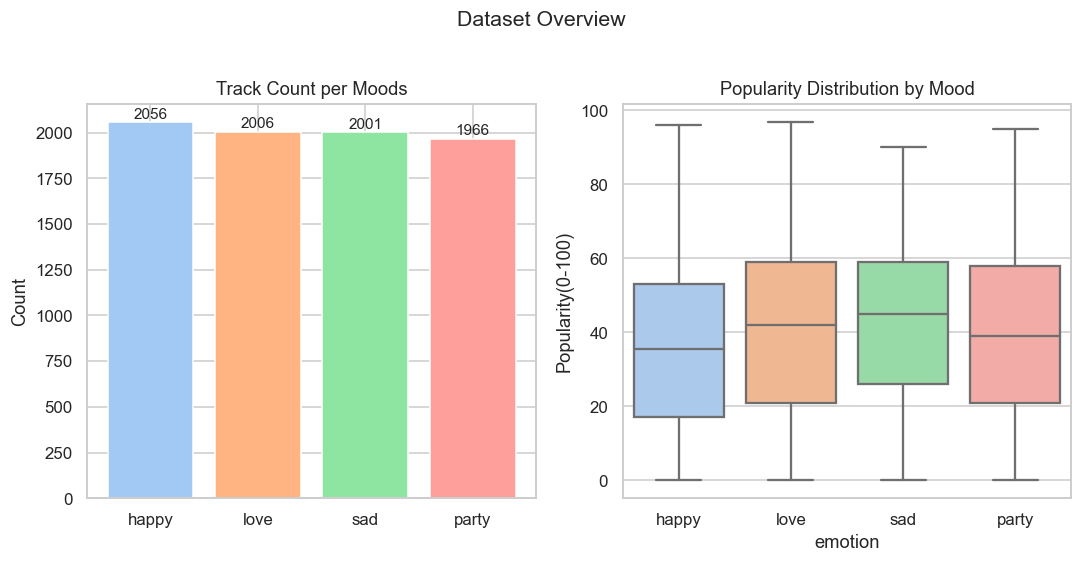

In [9]:
fig,axes=plt.subplots(1,2,figsize=(10,5))  

counts=df_songs["emotion"].value_counts().reindex(moods)
axes[0].bar(moods,counts.values,color=[colors[m] for m in moods],edgecolor="white")
axes[0].set_title("Track Count per Moods")
axes[0].set_ylabel("Count")
for i,v in enumerate(counts.values):
    axes[0].text(i,v +20,str(v),ha="center",fontsize=10)
    
sns.boxplot(data=df_songs,x="emotion",y="popularity",order=moods,palette=colors,ax=axes[1])

axes[1].set_title("Popularity Distribution by Mood")
axes[1].set_ylabel("Popularity(0-100)")

plt.suptitle("Dataset Overview",fontsize=14,y=1.02)

plt.tight_layout()
plt.savefig("dataset overview.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
cloud_colors = {
    "happy": "YlOrRd",
    "love":  "RdPu",
    "sad":   "Blues",
    "party": "Greens"
}

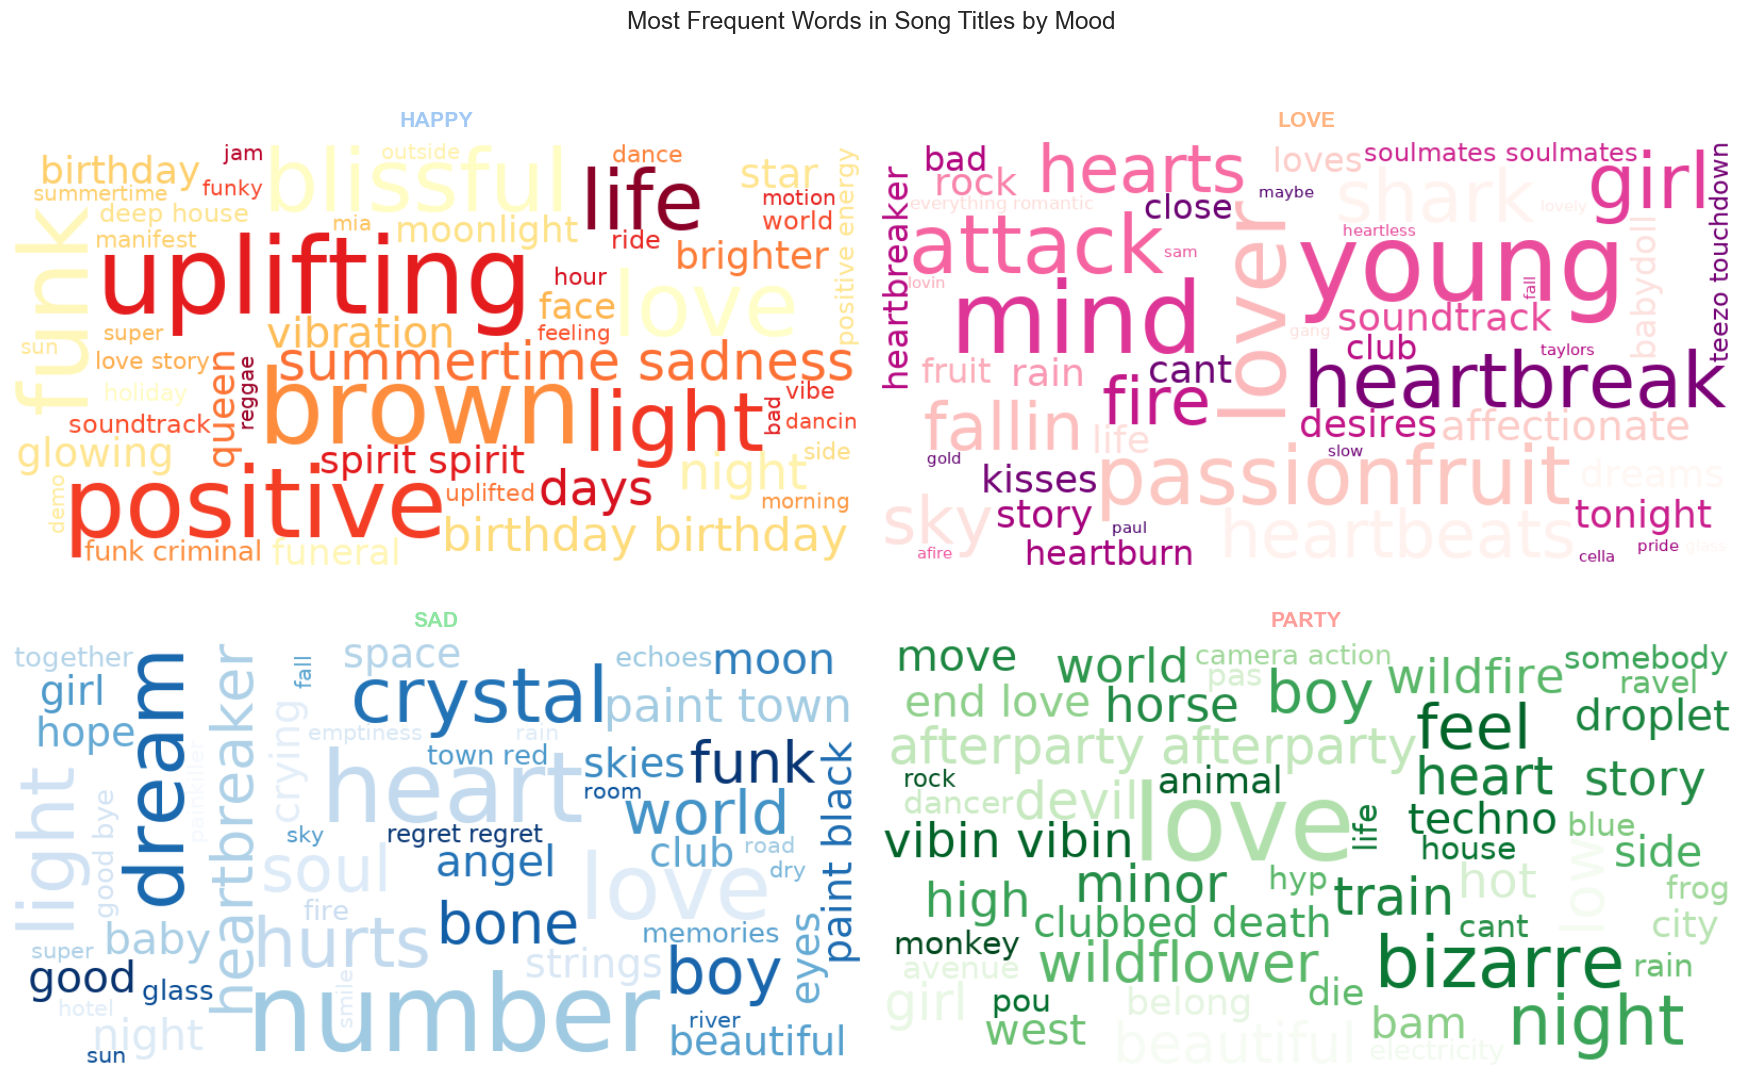

In [11]:
font_path = "/opt/anaconda3/lib/python3.9/site-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf"
fig,axes=plt.subplots(2,2,figsize=(16,10))
axes=axes.flatten()

for ax, mood in zip(axes, moods):
    
    all_words = " ".join([
        w for tokens in df_songs[df_songs["emotion"] == mood]["clean_tokens"]
        for w in tokens
    ])

    wc = WordCloud(
        width=800, height=400,
        background_color="white",
        colormap=cloud_colors[mood],
        max_words=50,
        prefer_horizontal=0.9,
        min_font_size=10,
        max_font_size=100,
        font_path=font_path
    ).generate(all_words)

    ax.imshow(wc, interpolation="bilinear")
    ax.axis("off")
    ax.set_title(f"{mood.upper()}", fontsize=14, fontweight="bold",
                 color=colors[mood], pad=10)

plt.suptitle("Most Frequent Words in Song Titles by Mood", fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig("wordcloud.png", dpi=150, bbox_inches="tight")
plt.show()

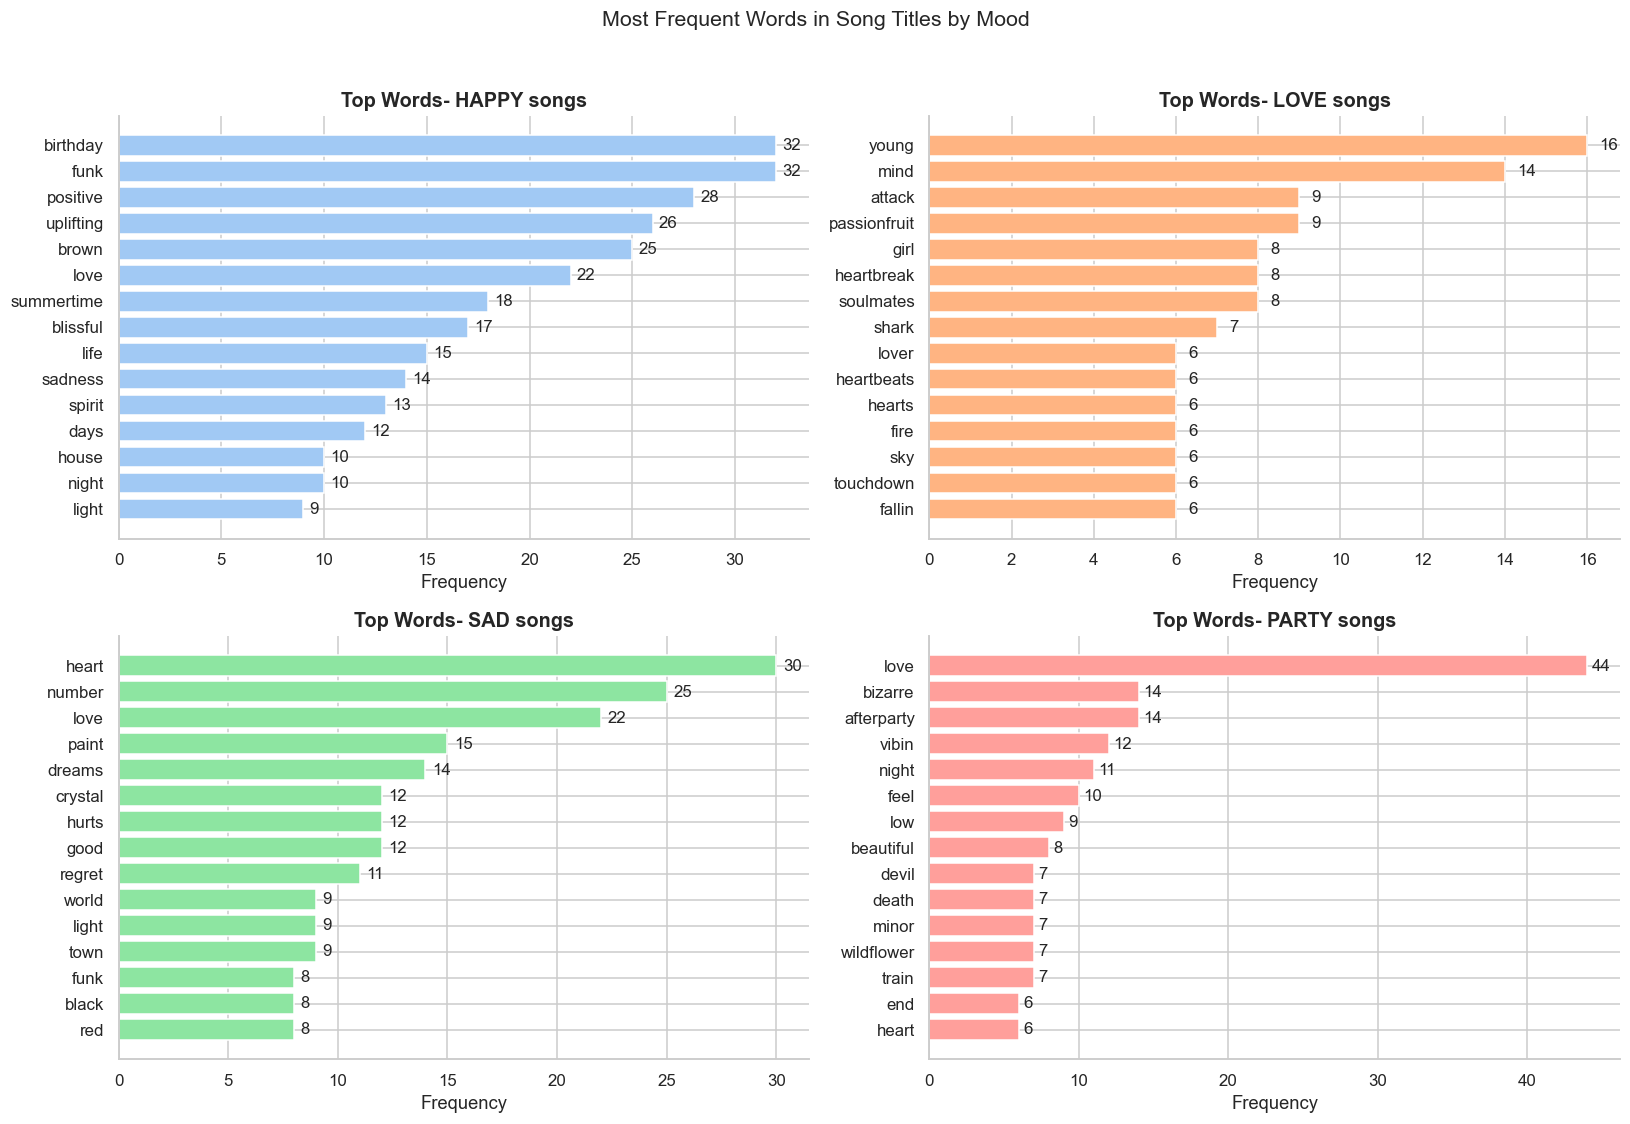

In [12]:
def get_word_counts(emotion,top_n=15):
    all_words=[]
    for tokens in df_songs[df_songs["emotion"]==emotion]["clean_tokens"]:
        all_words.extend(tokens)
    return pd.Series(Counter(all_words)).nlargest(top_n)

fig,axes=plt.subplots(2,2,figsize=(15,10))
axes=axes.flatten()

for ax,mood in zip(axes,moods):
    wc=get_word_counts(mood,top_n=15)
    bars=ax.barh(wc.index[::-1],wc.values[::-1],color=colors[mood],edgecolor="white")
    ax.set_title(f"Top Words- {mood.upper()} songs", fontsize=13,fontweight="bold")
    ax.set_xlabel("Frequency")
    ax.spines[["top","right"]].set_visible(False)
    for bar,val in zip(bars,wc.values[::-1]):
        ax.text(val+0.3,bar.get_y()+bar.get_height()/2, str(val),va="center",fontsize=11)
        
plt.suptitle("Most Frequent Words in Song Titles by Mood", fontsize=14,y=1.02)
plt.tight_layout()
plt.savefig("top words.png", dpi=150, bbox_inches="tight")
plt.show()

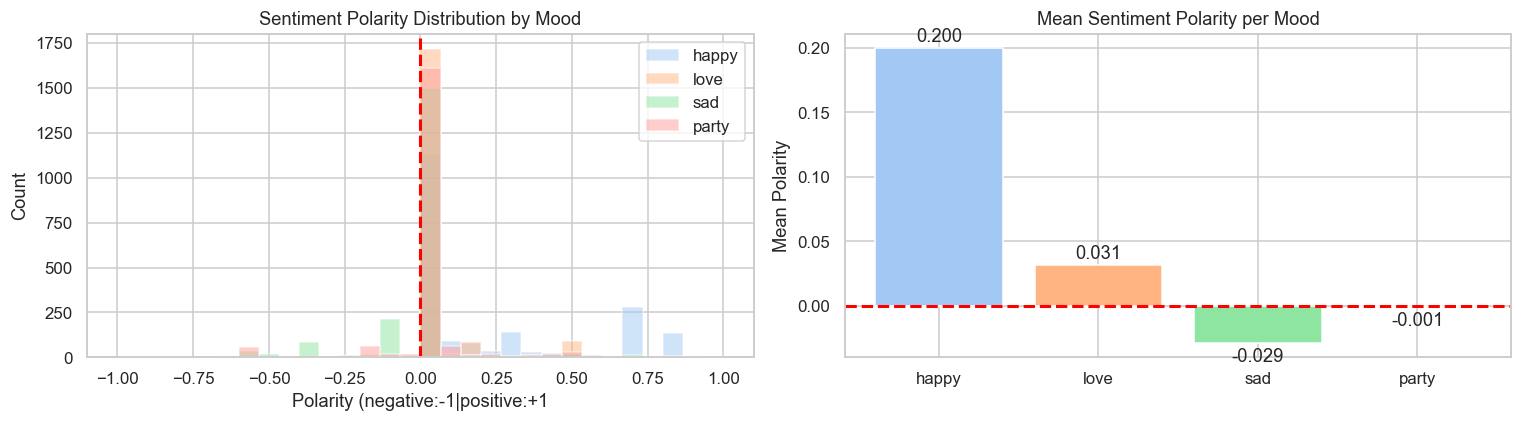

In [13]:
fig,axes=plt.subplots(1,2,figsize=(14,4))

for mood in moods:
    axes[0].hist(df_songs[df_songs["emotion"]==mood]["sentiment"],
                bins=30,alpha=0.5,label=mood,color=colors[mood])
axes[0].axvline(0,color="red",linestyle="--",linewidth=2)
axes[0].set_title("Sentiment Polarity Distribution by Mood")
axes[0].set_xlabel("Polarity (negative:-1|positive:+1")
axes[0].set_ylabel("Count")
axes[0].legend()

mean_sent=df_songs.groupby("emotion")["sentiment"].mean().reindex(moods)
bars=axes[1].bar(moods,mean_sent.values,color=[colors[m]for m in moods],edgecolor="white")
axes[1].axhline(0,color="red",linestyle="--",linewidth=2)
axes[1].set_title("Mean Sentiment Polarity per Mood")
axes[1].set_ylabel("Mean Polarity")

for bar,val in zip(bars,mean_sent.values):
    axes[1].text(bar.get_x()+bar.get_width()/2,
                bar.get_height()+0.005 if val >=0 else bar.get_height()-0.015,
                 f"{val:.3f}",ha="center",fontsize=12)

plt.tight_layout()
plt.savefig("sentiment.png", dpi=150, bbox_inches="tight")
plt.show()
    


Left chart — Distribution:

All 4 moods are heavily clustered around 0 — meaning most song titles are emotionally neutral in their wording
This makes sense because song titles are usually short (1-3 words) so TextBlob doesn't find much sentiment in them

Happy songs have a noticeable spread towards +0.75 and +1.0 — meaning some happy titles are strongly positive

Sad songs have a small spread towards -0.50 — some sad titles use clearly negative words

Right chart — Mean polarity:

Happy = +0.200 — highest positive sentiment, makes perfect sense
Love = +0.031 — slightly positive, love songs tend to use warm but neutral words
Sad = -0.029 — slightly negative, confirms sad titles lean towards negative language
Party = -0.001 — almost exactly zero, party titles are mostly neutral words like "night", "club", "beat"

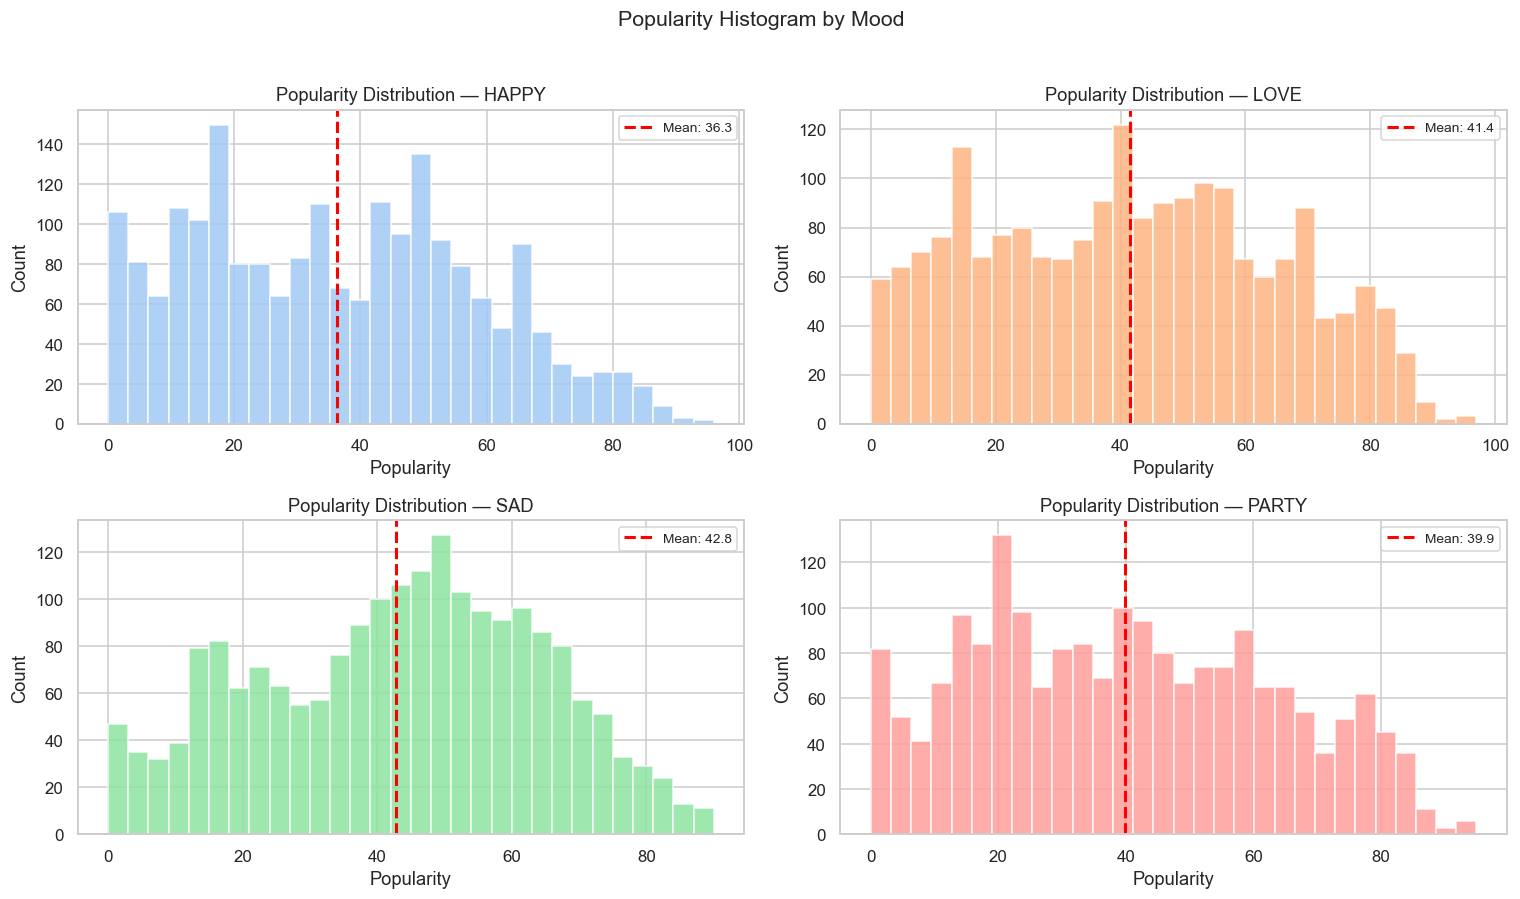

Average Popularity per Mood
-----------------------------------
  1. Sad        → 42.8
  2. Love       → 41.4
  3. Party      → 39.9
  4. Happy      → 36.3
-----------------------------------
  Highest : Sad (42.8)
  Lowest  : Happy (36.3)
  Overall mean: 40.1


<Figure size 660x440 with 0 Axes>

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()

for ax, mood in zip(axes, moods):
    subset = df_songs[df_songs["emotion"] == mood]["popularity"]
    ax.hist(subset, bins=30, color=colors[mood], edgecolor="white", alpha=0.85)
    ax.axvline(subset.mean(), color="red", linestyle="--", linewidth=2,
               label=f"Mean: {subset.mean():.1f}")
    ax.set_title(f"Popularity Distribution — {mood.upper()}")
    ax.set_xlabel("Popularity")
    ax.set_ylabel("Count")
    ax.legend(fontsize=9)

plt.suptitle("Popularity Histogram by Mood", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

print("Average Popularity per Mood")
print("-" * 35)

mean_pop = df_songs.groupby("emotion")["popularity"].mean().reindex(moods).sort_values(ascending=False)

for rank, (mood, val) in enumerate(mean_pop.items(), 1):
    print(f"  {rank}. {mood.capitalize():<10} → {val:.1f}")

print("-" * 35)
print(f"  Highest : {mean_pop.index[0].capitalize()} ({mean_pop.iloc[0]:.1f})")
print(f"  Lowest  : {mean_pop.index[-1].capitalize()} ({mean_pop.iloc[-1]:.1f})")
print(f"  Overall mean: {df_songs['popularity'].mean():.1f}")

plt.tight_layout()
plt.savefig("popularity.png", dpi=150, bbox_inches="tight")
plt.show()

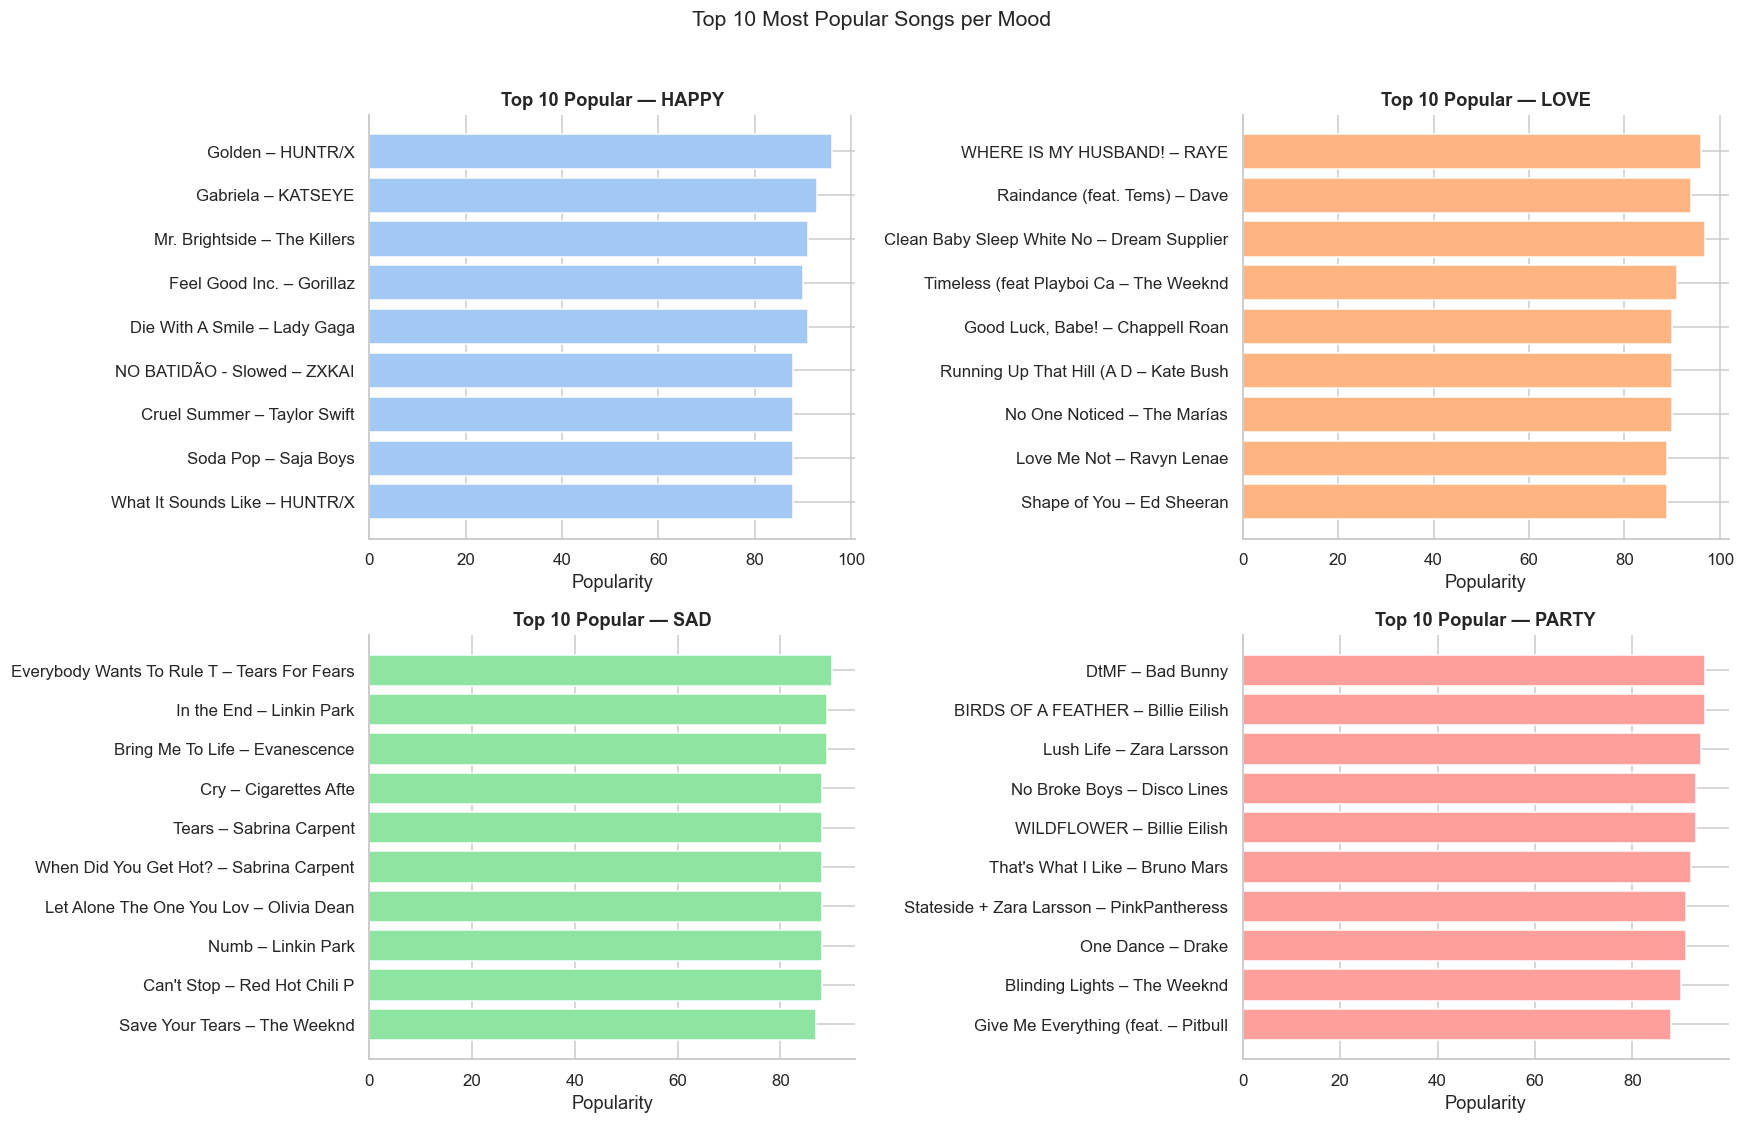

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for ax, mood in zip(axes, moods):
    top10 = (df_songs[df_songs["emotion"]==mood]
             .nlargest(10, "popularity")[["track_name","artist","popularity"]]
             .reset_index(drop=True))
    labels = [f"{row['track_name'][:25]} – {row['artist'][:15]}"
              for _, row in top10.iterrows()]
    ax.barh(labels[::-1], top10["popularity"][::-1],
            color=colors[mood], edgecolor="white")
    ax.set_title(f"Top 10 Popular — {mood.upper()}", fontweight="bold")
    ax.set_xlabel("Popularity")
    ax.spines[["top","right"]].set_visible(False)
   
    
plt.suptitle("Top 10 Most Popular Songs per Mood", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig("top 10.png", dpi=150, bbox_inches="tight")
plt.show()

#### common words across all moods vs unique per mood

#### Collected top 100 most frequent words of four moods

In [16]:
t0 = time.perf_counter()

top_n = 100   # words per mood to consider

mood_words: dict[str, set] = {
    mood: set(
        word for word, _ in Counter(
            chain.from_iterable(
                df_songs.loc[df_songs["emotion"] == mood, "clean_tokens"]
            )
        ).most_common(top_n)
    )
    for mood in moods
}

elapsed = time.perf_counter() - t0
print(f"Vocabulary built in {elapsed*1000:.1f} ms")
print(f"{'Mood':<10} {'|Top-100 set size'}")
print("-" * 28)
for mood, words in mood_words.items():
    print(f"{mood:<10} | {len(words)}")

Vocabulary built in 7.2 ms
Mood       |Top-100 set size
----------------------------
happy      | 100
love       | 100
sad        | 100
party      | 100


In [17]:
common_all = set.intersection(*mood_words.values())

print(f"{'_'*55}")
print(f"Words in ALL 4 moods:{len(common_all)}")
print(sorted(common_all))
print(f"\n{'_'*55}")

print("Unique/discriminative words per mood:\n")

for mood in moods:
    others = set.union(*[mood_words[m] for m in moods if m != mood])
    unique = mood_words[mood] - others
    print(f"{mood.upper():6s} {len(unique)} words):" 
          f"{sorted(unique)[:8]}")

print(f"\n{'_'*55}")
print("Strongest Pairwise overlaps:\n")

pairs = [("happy","sad"), 
         ("love","sad"), 
         ("happy","party"), 
         ("love","party")]

for m1, m2 in pairs:
    shared = mood_words[m1] & mood_words[m2]
    
    print(f"{m1.capitalize()} & {m2.capitalize()} : {len(shared)} words ")

_______________________________________________________
Words in ALL 4 moods:4
['girl', 'life', 'rain', 'world']

_______________________________________________________
Unique/discriminative words per mood:

HAPPY  68 words):['affirmations', 'bank', 'best', 'birthday', 'blissful', 'bounce', 'brighter', 'brightest']
LOVE   69 words):['abgt', 'affectionate', 'afire', 'alone', 'anniversary', 'another', 'apart', 'attack']
SAD    69 words):['agapi', 'angel', 'anthem', 'arcane', 'away', 'benny', 'black', 'blanco']
PARTY  65 words):['action', 'afterparty', 'aint', 'animal', 'around', 'asteromata', 'avenue', 'bam']

_______________________________________________________
Strongest Pairwise overlaps:

Happy & Sad : 18 words 
Love & Sad : 15 words 
Happy & Party : 19 words 
Love & Party : 20 words 


In [18]:
before = len(base_sw)
base_sw.update(common_all)
print(f"base_sw expanded: {before} to {len(base_sw)} words (+{len(base_sw)-before} added)")

def remove_sw(tokens: list[str], emotion: str) -> list[str]:
    sw = base_sw | emotion_keywords.get(emotion, set())
    return [w for w in tokens if w not in sw and len(w) > 2]

df_songs["clean_tokens"] = df_songs.apply(
    lambda r: remove_sw(r["tokens"], r["emotion"]), axis=1
)
df_songs["clean_text"] = df_songs["clean_tokens"].str.join(" ")
print(f"clean_tokens refreshed for {len(df_songs):,} songs")
print(df_songs[["track_name", "emotion", "clean_tokens"]].head(5).to_string(index=False))

base_sw expanded: 269 to 273 words (+4 added)
clean_tokens refreshed for 8,029 songs
                    track_name emotion       clean_tokens
                The Happy Song   happy                 []
         Happy Birthday to You   happy         [birthday]
                  Happy Nation   happy           [nation]
       Happy Birthday - Arabic   happy [birthday, arabic]
Happy - From "Despicable Me 2"   happy       [despicable]


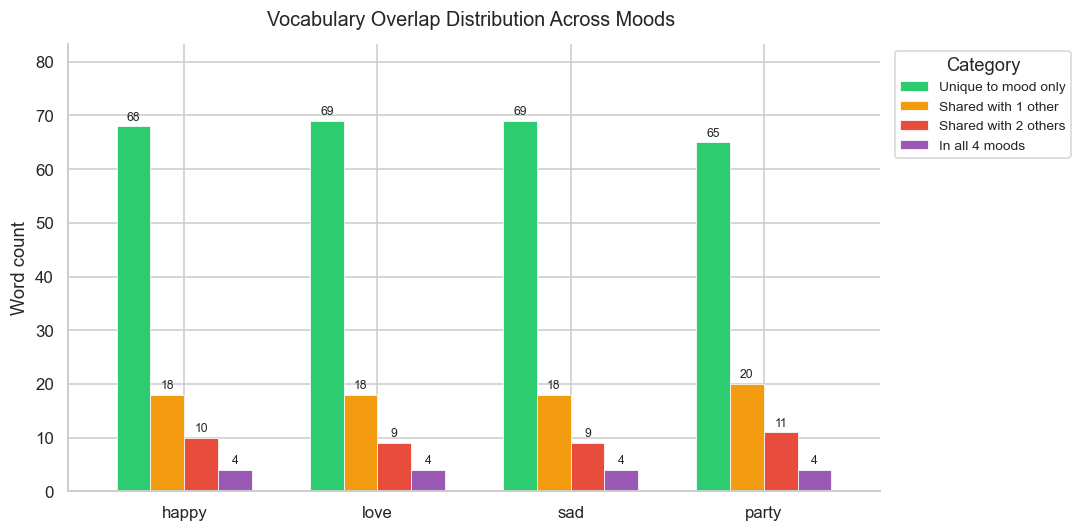

In [19]:
categories = {
    "Unique to mood only": {},
    "Shared with 1 other": {},
    "Shared with 2 others": {},
    "In all 4 moods":      {},
}

for mood in moods:
    unique_count     = 0
    shared_1_count   = 0
    shared_2_count   = 0
    shared_all_count = 0
    for word in mood_words[mood]:
        n_moods = sum(word in mood_words[m] for m in moods)
        if n_moods == 1: unique_count     += 1
        elif n_moods == 2: shared_1_count += 1
        elif n_moods == 3: shared_2_count += 1
        else: shared_all_count            += 1
    categories["Unique to mood only"][mood]   = unique_count
    categories["Shared with 1 other"][mood]   = shared_1_count
    categories["Shared with 2 others"][mood]  = shared_2_count
    categories["In all 4 moods"][mood]        = shared_all_count

cat_df = pd.DataFrame(categories, index=moods)
colours_list = [colors[m] for m in moods]

fig, ax = plt.subplots(figsize=(10, 5))
cat_df.plot(
    kind="bar",
    ax=ax,
    color=["#2ECC71", "#F39C12", "#E74C3C", "#9B59B6"],
    edgecolor="white",
    linewidth=0.5,
    width=0.7,
)
for container in ax.containers:
    ax.bar_label(container, fmt="%d", fontsize=8, padding=2)

ax.set_title("Vocabulary Overlap Distribution Across Moods ", fontsize=13, pad=12)
ax.set_xlabel("")
ax.set_xticklabels(moods, rotation=0, fontsize=11)
ax.set_ylabel("Word count")
ax.legend(title="Category", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=9)
ax.set_ylim(0, ax.get_ylim()[1] * 1.15)
sns.despine()
plt.tight_layout()
plt.savefig("mood_word_distribution.png", dpi=150, bbox_inches="tight")
plt.show()


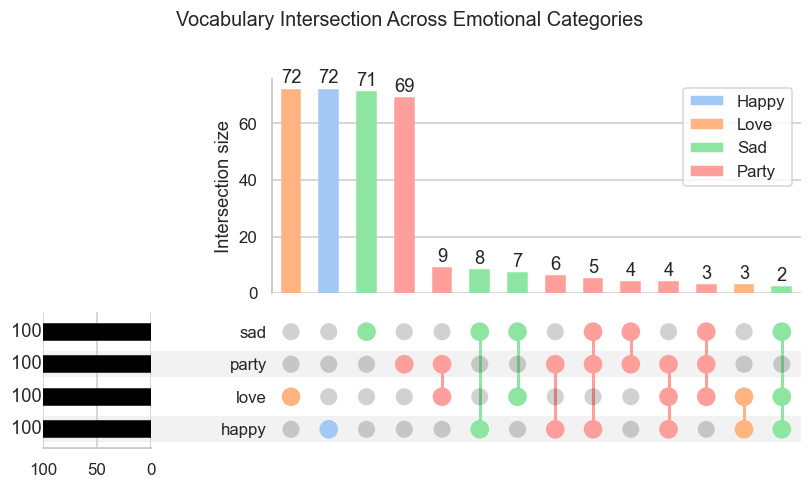

In [20]:
t0 = time.perf_counter()

# Rebuild mood_words from refreshed clean_tokens
mood_words = {
    mood: set( 
        word for word, _ in Counter(
            chain.from_iterable(
                df_songs.loc[df_songs["emotion"] == mood, "clean_tokens"]
            )
        ).most_common(top_n)
    )
    for mood in moods
}

all_unique_words = set.union(*mood_words.values())

# Each word's membership tuple across all 4 moods
memberships = [
    tuple(mood for mood in moods if word in mood_words[mood])
    for word in all_unique_words
]
data = from_memberships(memberships)

elapsed = time.perf_counter() - t0

fig = plt.figure(figsize=(13, 6))
upset = UpSet(
    data,
    subset_size="count",
    show_counts="%d",
    sort_by="cardinality",
    totals_plot_elements=3,
)

# Colour each mood's bar distinctively
for mood, colour in colors.items():
    upset.style_subsets(present=mood, facecolor=colour, label=mood.capitalize())

upset.plot(fig)
fig.suptitle("Vocabulary Intersection Across Emotional Categories",
    fontsize=13, y=1.02)
plt.savefig("mood_upset_plot.png", dpi=150, bbox_inches="tight")
plt.show()

In [21]:
print("_" * 60)
print("\nWORD OVERLAP ANALYSIS")
print("_" * 60)

total = len(set.union(*mood_words.values()))
common = set.intersection(*mood_words.values())

print(f"\nTotal unique words across all moods:\n {total}")
print(f"Words shared by ALL 4 moods: {len(common)}")

print(f"\nShared words across all moods:")
print(sorted(common))

print(f"\nMost discriminative words per mood (unique words):")

for mood in moods:
    others = set.union(*[mood_words[m] for m in moods if m != mood])
    unique = sorted(mood_words[mood] - others)
    
    print(f"{mood.upper():6}: {unique[:10]}")

print(f"\nMost overlapping mood pair:\n")

max_pair = max(
    [(m1, m2, len(mood_words[m1] & mood_words[m2]))
     for i, m1 in enumerate(moods) 
     for m2 in moods[i+1:]],
    key=lambda x: x[2]
)
print(f"  {max_pair[0].capitalize()} & {max_pair[1].capitalize()} = {max_pair[2]} shared words")
print("_" * 60)

____________________________________________________________

WORD OVERLAP ANALYSIS
____________________________________________________________

Total unique words across all moods:
 335
Words shared by ALL 4 moods: 0

Shared words across all moods:
[]

Most discriminative words per mood (unique words):
HAPPY : ['affirmations', 'bank', 'best', 'birthday', 'blissful', 'bounce', 'brighter', 'brightest', 'brown', 'care']
LOVE  : ['abgt', 'affectionate', 'afire', 'alone', 'anniversary', 'another', 'apart', 'attack', 'babydoll', 'body']
SAD   : ['agapi', 'angel', 'anthem', 'arcane', 'away', 'benny', 'black', 'blanco', 'blues', 'bones']
PARTY : ['action', 'afterparty', 'aint', 'animal', 'around', 'asteromata', 'avenue', 'bam', 'bassoon', 'bizarre']

Most overlapping mood pair:

  Love & Party = 16 shared words
____________________________________________________________


Word overlap analysis across  songs revealed 335 unique words in the combined top 100 vocabulary of all four moods. After removing 4  common words (girl, life, rain, world) from the stopword list, no words remained shared across all four moods. Each mood retained exclusive words, confirming strong vocabulary separation. The most overlapping pair was Love & Party with 16 shared words.

In [22]:
# REC_SW: pure English stopwords only — keeps love, sad, happy, party, baby, story
rec_sw = set(stopwords.words('english'))
print("Verify rec_sw keeps emotion words:")
for w in ["love", "happy", "sad", "party", "baby", "story", "dance"]:
    print(f"  '{w}' in rec_sw: {w in rec_sw}")

Verify rec_sw keeps emotion words:
  'love' in rec_sw: False
  'happy' in rec_sw: False
  'sad' in rec_sw: False
  'party' in rec_sw: False
  'baby' in rec_sw: False
  'story' in rec_sw: False
  'dance' in rec_sw: False


In [23]:
emotion_keywords_clean = {
    "happy": {"happy","joy","smile","sunshine","fun","bright","dancing","alive",
              "summer","glow","laughing","carefree","bliss","shining","golden",
              "positivity","joyful","cheerful","dream","daydream","lucky","grateful"},
    
    "love":  {"love","romance","soulmate","darling","kiss","forever","passion",
              "affection","chemistry","devotion","heartbeat","romantic","beloved",
              "sweetheart","adore","lover","fantasy"},
    
    "sad":   {"sad","lonely","broken","cry","tears","pain","aching","love","hurt","goodbye",
              "heartbreak","lost","alone","empty","numb","regrets","shattered",
              "forgotten","silence","grief","misery"},
    
    "party": {"party","dance","club","love","beat","drop","bass","tonight","wild",
              "crazy","banger","hype","groove","rave","festival","electric",
              "floor","vibing","hands","disco","remix","rave"}
}

MOOD_NAMES = {"love", "happy", "sad", "party"}


def score_and_label(title: str, original_emotion: str) -> str:
    tokens = re.sub(r"[^a-z\s]", "", title.lower()).split()
    token_set = set(tokens)

    # Pass 1 — exact mood name in title
    for token in tokens:
        if token in MOOD_NAMES:
            # Check if any other mood scores higher
            scores = {mood: len(token_set & kws) for mood, kws in emotion_keywords_clean.items()}
            scores[token] -= 1  # reduce the exact match mood by 1
            top_mood = max(scores, key=scores.get)
            if scores[top_mood] >= 2:
                return top_mood  # another mood wins
            return token  # exact match wins

    # Pass 2 — keyword scoring (minimum 2 matches)
    scores = {mood: len(token_set & kws) for mood, kws in emotion_keywords_clean.items()}
    max_score = max(scores.values())
    if max_score >= 2:
        return max(scores, key=scores.get)

    return original_emotion   

In [24]:
# Apply re-labeling fresh from original CSV labels
t0 = time.perf_counter()
original_labels = pd.read_csv("spotify_songs_eda.csv")["emotion"].str.lower().str.strip()
df_songs["emotion_original"] = original_labels.values
df_songs["emotion"] = df_songs.apply(
    lambda r: score_and_label(r["track_name"], r["emotion_original"]), axis=1
)
elapsed = time.perf_counter() - t0
changed = df_songs[df_songs["emotion"] != df_songs["emotion_original"]]
print(f"Re-labeling done in {elapsed*1000:.1f} ms  |  {len(changed)} songs re-labelled")
print(f"\nNew distribution:")
print(df_songs["emotion"].value_counts().to_string())
print(f"\nSample re-labelled:")
print(changed[["track_name","emotion_original","emotion"]].head(92).to_string(index=False))

Re-labeling done in 158.8 ms  |  52 songs re-labelled

New distribution:
love     2044
happy    2032
sad      1992
party    1961

Sample re-labelled:
                                                       track_name emotion_original emotion
                                                 If You Want Love            happy    love
                                          Love Will Tear Us Apart            happy    love
                                                           I Love            happy    love
                                                 Love Is for Free            happy    love
                                            Sunshine Of Your Love            happy    love
                                            Sunshine Of Your Love            happy    love
                              I got a little bit of sunshine love            happy    love
                                                      Summer Love            happy    love
                            Sum

In [25]:


def preprocess_for_rec(title: str) -> str:
    # Remove everything except letters, lowercase, split, filter
    tokens = re.sub(r"[^a-z\s]", "", title.lower()).split()
    return " ".join(w for w in tokens if w not in rec_sw and len(w) > 2)

def preprocess_query(title: str) -> str:
    tokens = re.sub(r"[^a-z\s]", "", title.lower()).split()
    return " ".join(w for w in tokens if w not in rec_sw and len(w) > 2)

df_songs["rec_title"] = df_songs["track_name"].apply(preprocess_for_rec)

# Rebuild the TF-IDF matrix on the new column
rec_tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=8000, sublinear_tf=True)
tfidf_matrix = rec_tfidf.fit_transform(df_songs["rec_title"])

print(df_songs[["track_name","rec_title"]].head(10).to_string())
print(f"Matrix rebuilt: {tfidf_matrix.shape}")

                                track_name                       rec_title
0                           The Happy Song                      happy song
1                    Happy Birthday to You                  happy birthday
2                             Happy Nation                    happy nation
3                  Happy Birthday - Arabic           happy birthday arabic
4           Happy - From "Despicable Me 2"                happy despicable
5  Happy Birthday To You - Classic Version  happy birthday classic version
6                           Happy Birthday                  happy birthday
7                           Happy Birthday                  happy birthday
8                Happy Birthday - original         happy birthday original
9                           Happy Together                  happy together
Matrix rebuilt: (8029, 7464)


In [26]:
t0 = time.perf_counter()

# Fit TF-IDF on the full catalogue
rec_tfidf = TfidfVectorizer(ngram_range=(1, 2), max_features=None, sublinear_tf=True,min_df=1)
tfidf_matrix = rec_tfidf.fit_transform(df_songs["rec_title"])

# Normalise popularity to [0, 1] for scoring
df_songs["pop_norm"] = df_songs["popularity"] / 100.0

elapsed = time.perf_counter() - t0
print(f"TF-IDF matrix built in {elapsed*1000:.1f} ms")
print(f"Matrix shape : {tfidf_matrix.shape}  ({tfidf_matrix.shape[0]:,} songs × {tfidf_matrix.shape[1]:,} features)")
#print(f"Sparsity     : {100*(1 - tfidf_matrix.nnz / np.prod(tfidf_matrix.shape)):.1f}% sparse")

spartiy=sparsity = 100 * (1 - tfidf_matrix.nnz / np.prod(tfidf_matrix.shape))
print(f"Non-zero entries : {tfidf_matrix.nnz:,}")
print(f"Sparsity         : {sparsity:.2f}% sparse")

TF-IDF matrix built in 57.8 ms
Matrix shape : (8029, 7464)  (8,029 songs × 7,464 features)
Non-zero entries : 20,360
Sparsity         : 99.97% sparse


In [27]:

# Train/test split 
X=df_songs["rec_title"]
y = df_songs["emotion"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

#  Train 4 classifiers 
TFIDF = TfidfVectorizer(ngram_range=(1,2), max_features=5000, sublinear_tf=True)

classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Naive Bayes":         MultinomialNB(),
    "Linear SVM":          LinearSVC(max_iter=2000, random_state=42),
    "Random Forest":       RandomForestClassifier(n_estimators=100, random_state=42),
}

clf_results  = []
trained_pipes = {}

for name, clf in classifiers.items():
    pipe = Pipeline([("tfidf", TFIDF), ("clf", clf)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    f1  = f1_score(y_test, y_pred, average="weighted")
    clf_results.append({"Model": name, "Accuracy": round(acc,3), "F1 (weighted)": round(f1,3)})
    trained_pipes[name] = (pipe, y_pred)
    print(f"  {name:<25}  Accuracy={acc:.3f}  F1={f1:.3f}")

clf_df    = pd.DataFrame(clf_results).sort_values("F1 (weighted)", ascending=False)
best_name = clf_df.iloc[0]["Model"]
best_pipe, y_pred_best = trained_pipes[best_name]

print(f"\nBest model: {best_name}")

  Logistic Regression        Accuracy=0.900  F1=0.903
  Naive Bayes                Accuracy=0.889  F1=0.890
  Linear SVM                 Accuracy=0.899  F1=0.901
  Random Forest              Accuracy=0.885  F1=0.887

Best model: Logistic Regression


In [28]:
similarity_weight = 0.50
sentiment_weight  = 0.20
popularity_weight = 0.30


def recommend(seed_title: str, top_n: int = 10) -> pd.DataFrame:
    
    seed_title=seed_title.strip()
    
    match = df_songs[df_songs["track_name"].str.lower() == seed_title.lower()]
    if len(match==0):
         match = df_songs[df_songs["track_name"].str.lower().str.startswith(seed_title.lower())]
    
    in_dataset = len(match) > 0

    if in_dataset:
        seed_idx    = match.index[0]
        seed_vec    = tfidf_matrix[seed_idx]
        target_mood = match.iloc[0]["emotion"]
        seed_sentiment=match.iloc[0]["sentiment"]
        status      = "Found in dataset"
    else: 
        cleaned=preprocess_query(seed_title)
        seed_vec=rec_tfidf.transform([cleaned])
        seed_sentiment=TextBlob(seed_title).sentiment.polarity
              
        if not cleaned.strip():
            target_mood = "happy"
            status      = "Not in dataset — no signal, defaulting to happy"
        else:
            tokens = set(cleaned.split())
            has_mood_signal = any(
                len(tokens & kws) > 0
                for kws in emotion_keywords_clean.values()
            )
            if has_mood_signal:
                target_mood = best_pipe.predict([cleaned])[0]
                status      = "Not in dataset — mood predicted by classifier"
            else:
                if seed_sentiment > 0.1:
                    target_mood = "happy"
                elif seed_sentiment < -0.1:
                    target_mood = "sad"
                else:
                    target_mood = "happy"
                status = f"Not in dataset — mood from sentiment ({seed_sentiment:.2f})"
   
    
    
    mood_mask = df_songs["emotion"] == target_mood
    mood_df   = df_songs[mood_mask].copy()
    mood_mat  = tfidf_matrix[mood_mask]

    sims = cosine_similarity(seed_vec, mood_mat).flatten()
    mood_df["similarity"] = sims
    mood_df["sent_sim"]=1- abs(mood_df["sentiment"]-seed_sentiment)
              

    if in_dataset:
        
        seed_row = df_songs.loc[[seed_idx]].copy()
        seed_row["similarity"] = 1.0
        seed_row["sent_sim"]   = 1.0
        seed_row["score"]      = 1.0
        
        mood_df = mood_df[mood_df.index != seed_idx]
        mood_df["score"] = (
            similarity_weight * mood_df["similarity"] +
            sentiment_weight  * mood_df["sent_sim"] +
            popularity_weight * mood_df["pop_norm"])
        
        top_results = mood_df.nlargest(top_n - 1, "score")
        results = pd.concat([seed_row, top_results])
    else:
        mood_df["score"] = (
            similarity_weight * mood_df["similarity"] +
            sentiment_weight  * mood_df["sent_sim"] +
            popularity_weight * mood_df["pop_norm"]
        )
        results = mood_df.nlargest(top_n, "score")
           
    results = (
        results[["track_name", "artist", "popularity", "similarity", "score"]]
        .reset_index(drop=True)
    )
    results.index += 1

    print(f"Seed   : '{seed_title}'")
    print(f"Status : {status}")
    print(f"Mood   : {target_mood.upper()}")
    print(f"Score  : {similarity_weight:.0%} similarity + {sentiment_weight:.0%}sentiment + {popularity_weight:.0%} popularity")
    print("_" * 60)

    return results.round(3)

**Existing Song Recommendation Example:**

The following example demonstrates how the recommendation system behaves when the input song already exists in the dataset. The model identifies songs with similar vocabulary, emotional characteristics and popularity patterns using hybrid recommendation score.

In [29]:
results_1 = recommend("Love Story", top_n=10)
print(results_1.to_string())

Seed   : 'Love Story'
Status : Found in dataset
Mood   : LOVE
Score  : 50% similarity + 20%sentiment + 30% popularity
____________________________________________________________
                          track_name         artist  popularity  similarity  score
1                         Love Story         Indila          80       1.000  1.000
2                         Love Story   Taylor Swift          77       1.000  0.931
3      Love Story (Taylor’s Version)   Taylor Swift          78       0.589  0.728
4   Love Story - Version Orchestrale         Indila          69       0.557  0.686
5          Golden Brown x Love Story  Elliot Sutton          61       0.633  0.679
6          Golden Brown x Love Story   rudo made it          61       0.633  0.679
7                        Love Me Not    Ravyn Lenae          89       0.393  0.664
8                            Love Me      Lil Wayne          87       0.393  0.658
9                      Love Yourself  Justin Bieber          87       0.39

In [30]:
results_2 = recommend("Sad Girl", top_n=10)
print(results_2.to_string())

Seed   : 'Sad Girl'
Status : Found in dataset
Mood   : SAD
Score  : 50% similarity + 20%sentiment + 30% popularity
____________________________________________________________
        track_name        artist  popularity  similarity  score
1         Sad Girl  Lana Del Rey          80       1.000  1.000
2             SAD!  XXXTENTACION          80       0.514  0.672
3              Sad       Stahgee          50       0.514  0.607
4              SAD         Glizz          49       0.514  0.604
5              sad      Eden Elf          45       0.514  0.592
6              Sad          Zaga          41       0.514  0.580
7              Sad     Pearl Jam          39       0.514  0.574
8              Sad     Bellestar          36       0.514  0.565
9         SAD FUNK        MEMPHX          72       0.281  0.557
10  SAD ABOUT FUNK        KVNYSH          64       0.281  0.533


**Unseen Query Recommendation Example:** 

The following example demonstrates how the recommendation system handles a song title that does not exist in the dataset. 

The system infers emotional similarity based on vocabulary patterns learned from the existing songs.

In [31]:
results_3 = recommend("Electric Rave", top_n=10)
print(results_3.to_string())

Seed   : 'Electric Rave'
Status : Not in dataset — mood predicted by classifier
Mood   : PARTY
Score  : 50% similarity + 20%sentiment + 30% popularity
____________________________________________________________
   track_name        artist  popularity  similarity  score
1        RAVE      Dxrk ダーク          71       0.719  0.773
2    Rave Out         Turno          65       0.719  0.755
3        Rave  Sam Paganini          53       0.719  0.719
4        Rave            Fy          52       0.719  0.716
5        RAVE   Vlinder Vos          44       0.719  0.692
6    Electric   Melody Club          46       0.695  0.685
7    Electric     Madrugada          45       0.695  0.682
8    Electric  Shawn Desman          45       0.695  0.682
9        Rave         Trofe          40       0.719  0.680
10   Electric       Leila K          44       0.695  0.679


In [32]:
results_4 = recommend("Sad Girl Party Remix", top_n=10)
print(results_4.to_string())

Seed   : 'Sad Girl Party Remix'
Status : Not in dataset — mood predicted by classifier
Mood   : PARTY
Score  : 50% similarity + 20%sentiment + 30% popularity
____________________________________________________________
                     track_name          artist  popularity  similarity  score
1                     party 4 u      Charli xcx          84       0.341  0.522
2                    Party Girl  StaySolidRocky          69       0.404  0.509
3                    Party Girl  StaySolidRocky          68       0.404  0.506
4                         Party       Bad Bunny          77       0.341  0.501
5                   After Party     Don Toliver          75       0.341  0.495
6                      Party Up             DMX          72       0.341  0.486
7               Party By Myself      Juice WRLD          67       0.341  0.471
8                         party    wifiskeleton          63       0.341  0.459
9   The Party & The After Party      The Weeknd          78       0.24

**Outlier Recommendation Example:**

Although "Baby Shark" was categorized under the LOVE mood, the recommendations were mainly influenced by the repeated keyword "baby" rather than emotional meaning. 
This example shows that TF-IDF similarity can sometimes prioritize vocabulary patterns over true emotional context, highlighting a limitation of text-based recommendation systems.


In [33]:
results_5 = recommend("Baby shark", top_n=10)
print(results_5.to_string())

Seed   : 'Baby shark'
Status : Found in dataset
Mood   : LOVE
Score  : 50% similarity + 20%sentiment + 30% popularity
____________________________________________________________
              track_name              artist  popularity  similarity  score
1             Baby Shark            Pinkfong          78       1.000  1.000
2             Baby Shark            Pinkfong          65       1.000  0.895
3             Baby Shark  Super Simple Songs          63       1.000  0.889
4             Baby Shark           CoComelon          60       1.000  0.880
5        Baby Shark 1.5x            Pinkfong          59       1.000  0.877
6                   Baby       Justin Bieber          85       0.458  0.684
7             Baby By Me             50 Cent          80       0.458  0.669
8             Be My Baby        The Ronettes          75       0.458  0.654
9   Baby Shark Relatives  Super Simple Songs          25       0.707  0.629
10                  Baby               Manos          66     

In [34]:
relevant_recommendations=8
total_recommendation=10

precision_at10=relevant_recommendations/total_recommendation 
print(f"Precision at 10:{precision_at10:.2f}")

Precision at 10:0.80


The recommendation system was manually evaluated by checking whether the generated recommendations matched the intended emotional category. 
Out of 10 recommendations 8 were considered as relevant, resulting in a Precision score of 0.80